## Section 1: Setup and loading the data
This section imports the libraries, gives short names to the long column names (CO2, KW, MASS ...), looks for the CSV file next to the notebook and loads it.
**Why.** The file uses semicolons and French accents, so it must be read with `sep=";"` and `encoding="latin1"`, otherwise the columns and letters are wrong. Short names avoid typing mistakes. A relative path lets the notebook run on any computer.
**What we learn.** 44,850 rows and 26 columns: names, engine and gearbox, fuel consumption, lab pollutant outputs, mass, body type and the target CO2 (g/km).

In [ ]:
# SECTION 1 (code): setup and loading
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
from scipy import stats

# ---- Paths (relative, so the notebook runs on any machine and on GitHub) -----
FIG_DIR = "figures"
os.makedirs(FIG_DIR, exist_ok=True) 

# ---- Column names in one place --------------
CO2   = "CO2 (g/km)"
CONSO = "Consommation mixte (l/100km)"
KW    = "Puissance maximale (kW)"
MASS  = "masse vide euro min (kg)"
GEAR  = "Boîte de vitesse"

# Fuels used in the scatter plots: diesel (GO), petrol (ES), petrol-hybrid (EH).
# Together they cover approx. 99.5% of the rows. The other 9 fuel codes would only clutter the legend.
MAIN_FUELS = ["GO", "ES", "EH"]

# The data file: first look in the project's data folder (the notebook lives in notebooks/), then next to the notebook
DATA_CANDIDATES = ["../data/cl_JUIN_2013-complet3.csv",
                   "data/cl_JUIN_2013-complet3.csv",
                   "cl_JUIN_2013-complet3.csv"]
DATA_PATH = next((p for p in DATA_CANDIDATES if os.path.exists(p)), None)
if DATA_PATH is None:
    raise FileNotFoundError("Put cl_JUIN_2013-complet3.csv in the data/ folder of the project.")
df = pd.read_csv(DATA_PATH, encoding='latin1', sep=';')
print("Shape:", df.shape)
print("Columns:", df.columns.tolist())
print("\n")
print(df.head(2))
print(df.info())

Shape: (44850, 26)
Columns: ['Marque', 'Modèle dossier', 'Modèle UTAC', 'Désignation commerciale', 'CNIT', 'Type Variante Version (TVV)', 'Carburant', 'Hybride', 'Puissance administrative', 'Puissance maximale (kW)', 'Boîte de vitesse', 'Consommation urbaine (l/100km)', 'Consommation extra-urbaine (l/100km)', 'Consommation mixte (l/100km)', 'CO2 (g/km)', 'CO type I (g/km)', 'HC (g/km)', 'NOX (g/km)', 'HC+NOX (g/km)', 'Particules (g/km)', 'masse vide euro min (kg)', 'masse vide euro max (kg)', 'Champ V9', 'Date de mise à jour', 'Carrosserie', 'gamme']


       Marque Modèle dossier Modèle UTAC   Désignation commerciale  \
0  ALFA-ROMEO            159         159      159 1750 Tbi (200ch)   
1  ALFA-ROMEO            159         159  159 2.0 JTDm (170ch) ECO   

              CNIT Type Variante Version (TVV) Carburant Hybride  \
0  M10ALFVP000G340                 939AXN1B52C        ES     non   
1  M10ALFVP000U221                 939AXP1B54C        GO     non   

   Puissance administrati

## Section 2: Cleaning the data
This section removes the rows without a CO2 value (39 rows) and the exact duplicate rows (619 rows), so 44,850 rows become 44,192.
**Why.** A model learns from examples that have an answer, so rows without CO2 cannot be used. Duplicates would count the same car twice and could end up in both train and test, which makes the scores look better than they are. Duplicates are found by comparing ALL columns, so this step must come before any column is dropped.

In [2]:
# SECTION 2 (code): cleaning
print("Rows without CO2:", int(df[CO2].isna().sum()))
print("Exact duplicate rows:", int(df.dropna(subset=[CO2]).duplicated().sum()))

df_clean = df.dropna(subset=[CO2])                         # rows without the target cannot be used for learning
df_clean = df_clean.drop_duplicates().reset_index(drop=True)   # duplicates across ALL columns
print("Rows before / after cleaning:", len(df), "/", len(df_clean))

Rows without CO2: 39
Exact duplicate rows: 619
Rows before / after cleaning: 44850 / 44192


## Section 3: The target CO2, and consumption vs CO2
This section prints the main numbers of the target and plots mixed consumption against CO2 (diesel GO, petrol ES, petrol hybrid EH = 99.5% of the rows).
**Why.** We must know the shape of the target. CO2 has mean 199, median 203 and skewness -0.06 g/km, so it is close to symmetric and no transformation (for example a logarithm) is needed.
**What we learn.** Consumption and CO2 lie on an almost perfect line: burning a litre of fuel always makes the same amount of CO2. Consumption is therefore CO2 in other units, and a new design has no measured consumption yet, so it would be cheating to use it as a feature (see Section 9).

CO2 (g/km): mean 199, median 203, std 38, min 27, max 572, skewness -0.06
Share of the three main fuels (GO, ES, EH): 99.5%
Correlation consumption vs CO2: 0.97


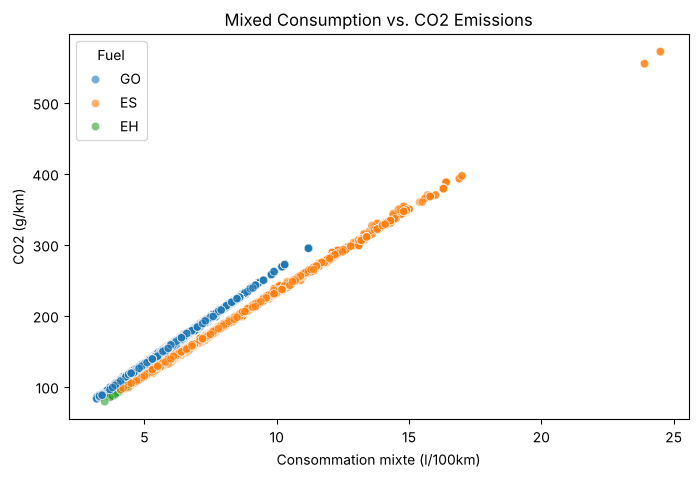

In [3]:
# SECTION 3 (code): target numbers and Figure 2 - consumption vs CO2
print(f"CO2 (g/km): mean {df_clean[CO2].mean():.0f}, median {df_clean[CO2].median():.0f}, "
      f"std {df_clean[CO2].std():.0f}, min {df_clean[CO2].min():.0f}, max {df_clean[CO2].max():.0f}, "
      f"skewness {df_clean[CO2].skew():.2f}")
print(f"Share of the three main fuels (GO, ES, EH): {df_clean['Carburant'].isin(MAIN_FUELS).mean() * 100:.1f}%")
print(f"Correlation consumption vs CO2: {df_clean[[CONSO, CO2]].corr().iloc[0, 1]:.2f}")

# Mixed consumption vs CO2, coloured by fuel (main fuels only, to keep the legend readable)
df_main = df_clean[df_clean["Carburant"].isin(MAIN_FUELS)]
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df_main, x=CONSO, y=CO2, hue="Carburant", hue_order=MAIN_FUELS, alpha=0.6)
plt.title("Mixed Consumption vs. CO2 Emissions")
plt.legend(title="Fuel")
plt.savefig(os.path.join(FIG_DIR, "Fig2_consumption_vs_co2.png"), dpi=300, bbox_inches="tight")
plt.show()
plt.close()

## Section 4: Correlation with CO2
This section shows how strongly each numeric column moves together with CO2 (correlation heatmap and sorted values).
**Why.** A first overview of what is related to CO2, and of columns that carry almost the same information as each other (for example the two mass columns correlate at 0.985, and the administrative power at 0.974 with kW). Redundant columns are candidates for removal.

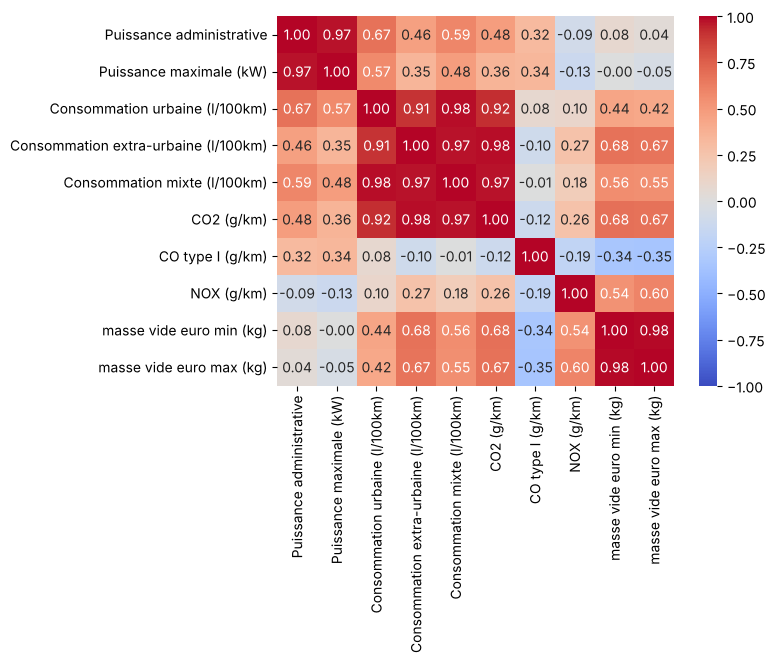

In [4]:
# SECTION 4 (code): correlation of the numeric columns with CO2
df_clean.select_dtypes("number").corr()["CO2 (g/km)"].sort_values(ascending=False)

df_test = df_clean.drop(columns=["HC (g/km)", "HC+NOX (g/km)", "Particules (g/km)"])

# Keeping numeric columns only (corr() can't use text)
num = df_test.select_dtypes("number")

# The correlation matrix
corr = num.corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.savefig(os.path.join(FIG_DIR, "Fig2_1_correlation_matrix.png"), dpi=300)
plt.show()
plt.close()

## Section 5: CO2 by fuel type, and engine power vs CO2
This section prints Box plots of CO2 for four fuel types and a scatter plot of power against CO2 with a trend line.
**What we learn.** Diesel and petrol have the same average (about 200 g/km) but petrol varies much more (standard deviation 66 vs 31 g/km); hybrids are lower (155 g/km on average). Across the three main fuels power and CO2 are positively but only loosely related (correlation 0.36); the relation is clearer once fuel and mass are separated (Section 8).
**Why it matters.** Fuel type and power are clearly useful features, and fuel must be considered when we look at power.

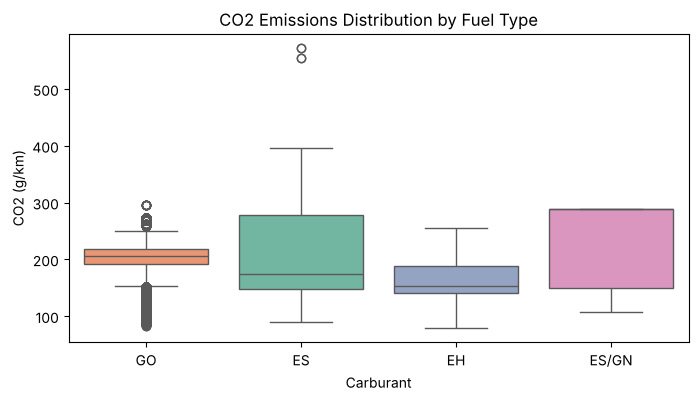

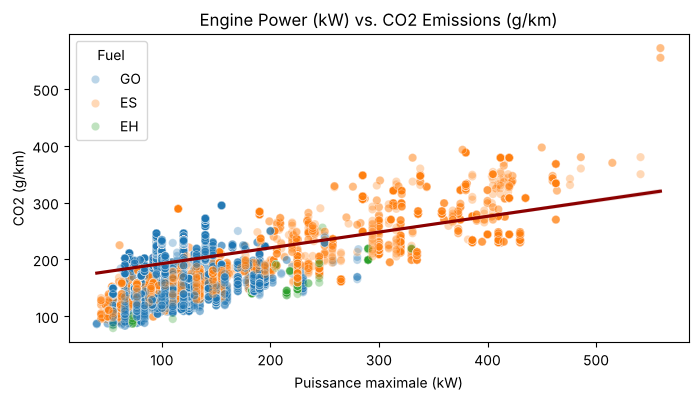

In [5]:
# SECTION 5 (code): Figure 3 (CO2 by fuel type) and Figure 4 (engine power vs CO2)

# 1. CO2 Emissions by Fuel Type
plt.figure(figsize=(8, 4))
top_fuels = ['GO', 'ES', 'EH', 'ES/GN']   # GO = diesel, ES = petrol, EH = petrol hybrid, ES/GN = petrol/natural gas

df_filtered_fuel = df_clean[df_clean['Carburant'].isin(top_fuels)]
sns.boxplot(x="Carburant", y=CO2, data=df_filtered_fuel, order=top_fuels, hue="Carburant", palette="Set2", legend=False)
plt.title('CO2 Emissions Distribution by Fuel Type')
plt.savefig(os.path.join(FIG_DIR, "Fig3_co2_fuel.png"), bbox_inches='tight', dpi=300)
plt.show()
plt.close()

# 2. Engine Power vs CO2 Emissions
plt.figure(figsize=(8, 4))
sns.scatterplot(x=KW, y=CO2, data=df_main, hue="Carburant", hue_order=MAIN_FUELS, alpha=0.3, legend=True)
sns.regplot(x=KW, y=CO2, data=df_main, scatter=False, color="darkred")
plt.legend(title="Fuel", loc="upper left")
plt.title("Engine Power (kW) vs. CO2 Emissions (g/km)")
plt.savefig(os.path.join(FIG_DIR, "Fig4_power_co2.png"), bbox_inches='tight', dpi=300)
plt.show()
plt.close()

## Section 6: Transmission and consumption
This section average mixed consumption of the five most common gearbox codes with 95% confidence intervals (M = manual, A = automatic, the number = gears).
**What we learn.** M 5 = 5.4, M 6 = 7.2, A 6 = 7.4, A 7 = 7.4, A 5 = 8.8 l/100 km. This is an association, not proof that the gearbox causes it (gearbox type also goes with the kind of car).
**Why it matters.** The gearbox code holds two facts (type and number of gears), so later we split it into two features.

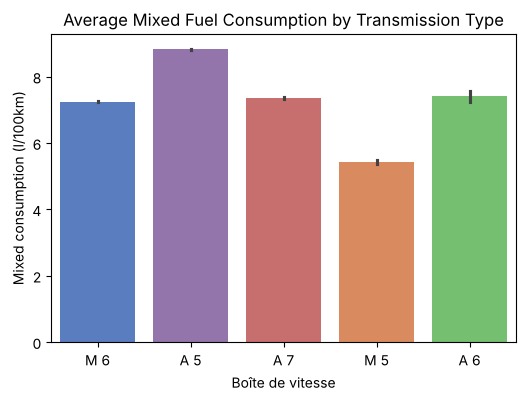

In [6]:
# SECTION 6 (code): Figure 5 - transmission type vs mixed fuel consumption

plt.figure(figsize=(6, 4))
top_trans = ['M 6', 'A 5', 'A 7', 'M 5', 'A 6']
df_filtered_trans = df_clean[df_clean[GEAR].isin(top_trans)]

# errorbar=("ci", 95) draws the 95% confidence interval of each mean (the thin black line on each bar)
sns.barplot(x=GEAR, y=CONSO, data=df_filtered_trans, order=top_trans,
            hue=GEAR, palette="muted", legend=False, errorbar=("ci", 95))
plt.title('Average Mixed Fuel Consumption by Transmission Type')
plt.ylabel("Mixed consumption (l/100km)")
plt.savefig(os.path.join(FIG_DIR, "Fig5_trans_fuel.png"), bbox_inches='tight', dpi=300)
plt.show()
plt.close()

## Section 7: Brands
This section averages CO2 of the 36 brands with at least 30 rows.
**What we learn.** Highest: Aston Martin (325 g/km), Cadillac (251), Mercedes AMG (241), Porsche (235). Lowest: Smart (110), Dacia (126), SEAT (127), Suzuki (132). Brand follows from the kind of cars a brand sells.
**Why it matters.** About 87% of the rows are Mercedes-Benz, so the data are unbalanced. We handle this later (sample weights, Section 13) and we do not use the brand as a feature (Section 9).

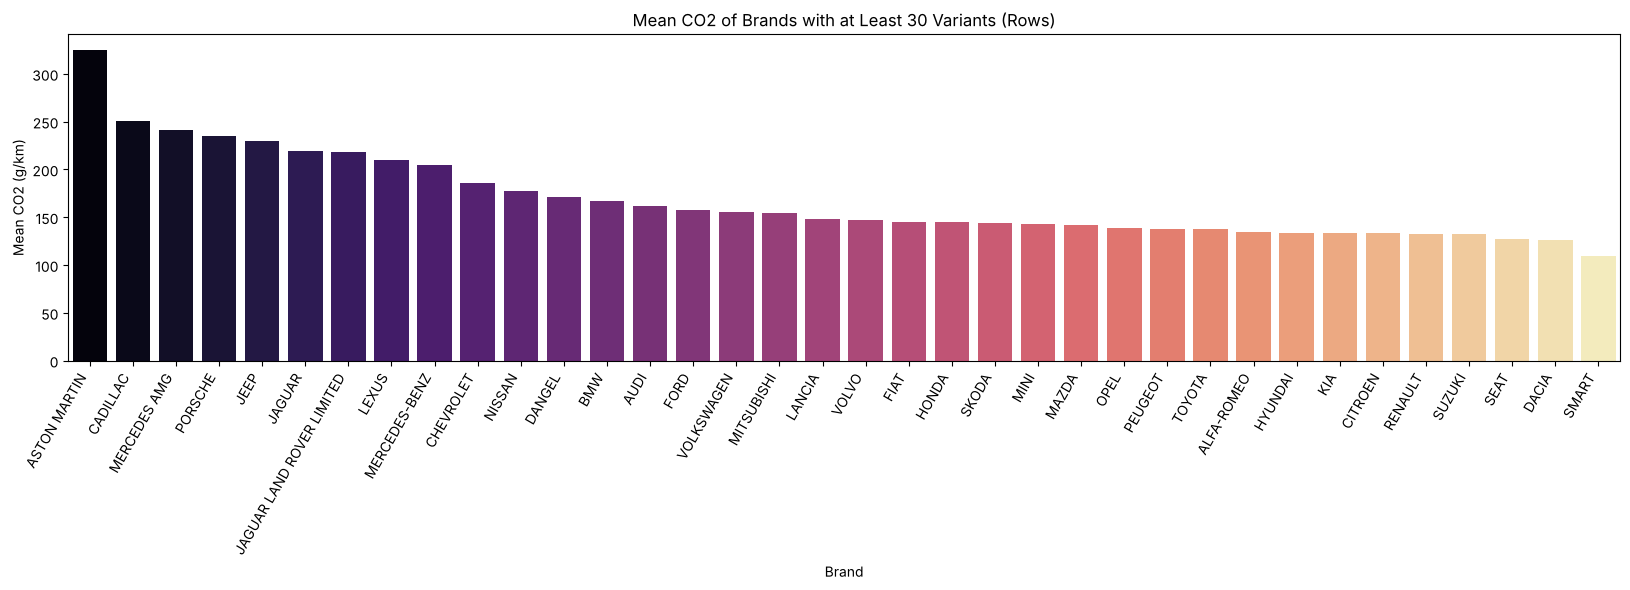

In [7]:
# SECTION 7 (code): Figure 6 - mean CO2 of the brands with at least 30 rows

MIN_ROWS = 30   # minimum number of rows a brand needs to be included

# Count rows per brand and keep only brands with at least MIN_ROWS
brand_counts = df_clean['Marque'].value_counts()
selected_makes = brand_counts[brand_counts >= MIN_ROWS].index
df_filtered_makes = df_clean[df_clean['Marque'].isin(selected_makes)]
# Mean CO2 per brand, sorted high → low
brand_co2 = (df_filtered_makes.groupby('Marque')['CO2 (g/km)']
             .mean()
             .sort_values(ascending=False)
             .reset_index())

# Make the figure taller as the number of brands grows
plt.figure(figsize=(0.4 * len(brand_co2) + 2, 6))
sns.barplot(x='Marque', y='CO2 (g/km)', data=brand_co2,
            palette='magma', hue='Marque', legend=False)
plt.xticks(rotation=60, ha='right')          # tilt the brand names so they don't overlap
plt.xlabel('Brand')
plt.ylabel('Mean CO2 (g/km)')
plt.title(f'Mean CO2 of Brands with at Least {MIN_ROWS} Variants (Rows)')
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "Fig6_maker_meanCO2.png"), bbox_inches='tight', dpi=300)
plt.show()
plt.close()

## Section 8: Mass and power vs CO2, by fuel, with and without Mercedes
This section prints A table of Spearman correlations between CO2 and (a) mass and (b) power, for diesel and petrol, once with all rows and once without Mercedes. (The mass used here is the minimum mass; the model uses the maximum mass, which correlates with it almost perfectly.)
**Why Spearman.** It uses ranks, so it is robust to outliers and to curved relations. **Why with / without Mercedes.** Mercedes is 87% of the data (three van models alone are 73%); leaving it out shows which findings are robust.
**What we learn.** Heavier and more powerful cars emit more in all four cases. For petrol both correlations are high with and without Mercedes. For diesel, mass and especially power are much weaker when the vans are included, because the vans are heavy but have a modest power, so they hide the pattern. This is why the vans need special care in the next sections (sample weights, Section 13).

In [8]:
# SECTION 8 (code): Spearman correlation of mass and power with CO2, with and without Mercedes
fuels = {"GO": "Diesel (GO)", "ES": "Petrol (ES)"}      # the other fuel codes have too few rows for a reliable correlation
rows = []
for code_, label in fuels.items():
    s = df_clean[df_clean["Carburant"] == code_]                    # all rows of this fuel
    o = s[s["Marque"] != "MERCEDES-BENZ"]                           # the same rows without Mercedes
    for col, name in [(MASS, "mass"), (KW, "power")]:
        rows.append({"fuel": label, "feature": name,
                     "rows (all)": len(s), "rows (no Mercedes)": len(o),
                     "Spearman (all rows)": stats.spearmanr(s[col], s[CO2])[0],
                     "Spearman (no Mercedes)": stats.spearmanr(o[col], o[CO2])[0]})
print(pd.DataFrame(rows).round(2).to_string(index=False))

       fuel feature  rows (all)  rows (no Mercedes)  Spearman (all rows)  Spearman (no Mercedes)
Diesel (GO)    mass       37680                3200                 0.61                    0.81
Diesel (GO)   power       37680                3200                 0.05                    0.38
Petrol (ES)    mass        6108                2490                 0.86                    0.87
Petrol (ES)   power        6108                2490                 0.77                    0.90


## Section 9: Choosing the features
**The rule.** A feature may only be used if an engineer knows it BEFORE the car exists. Anything measured in the same lab test as CO2, or computed from CO2, is not available for a new design.
**Order of the steps.** (1) Build two features from raw columns. (2) Split into train and test by car model. (3) Test the features by ablation on the training part only. (4) Drop the other columns, each with a reason. The split comes BEFORE the ablation, so the test cars play no role in choosing the features.
**The split.** Variants of one car model are nearly identical. With a random row split, a model could memorise a car's siblings and look brilliant on the test, which says nothing about a truly NEW design. `GroupShuffleSplit` (80% / 20%, random_state = 42) puts all variants of a car model on the same side, so the test cars are models the model has never seen. The test set is not touched until the final evaluation (Section 16).
**The ablation.** We train the same model (HistGradientBoosting) with and without a column and compare the error: grouped 5-fold cross-validation on the training part, 3 repeats with different fold assignments, metric MAE in g/km. The reference is the CORE model with the 7 kept features. A change smaller than about one standard deviation (the +- value) is noise. Columns that are not known before the car exists (consumption, administrative power, NOX) may lower the error, but they stay out whatever their score.
**What is kept (7 features).** Power, mass (max), number of gears, fuel, gearbox type, body type, hybrid. Read the table: removing a strong feature raises the error clearly; body type and hybrid show little effect, but they are kept because body style (drag, frontal area) and electric assist are physical drivers known at design time, and Hybride is almost the same information as the fuel code (Section 10).
**Brand.** Adding the brand lowers the error slightly (see the table), but we leave it out on purpose: it identifies the maker, not the design of the car, and about 87% of the rows are Mercedes-Benz, so it would mostly mean "Mercedes or not". We want a model that works from design information.

In [9]:
# SECTION 9 (code), step 1: build the two features, then SPLIT BY CAR MODEL
from sklearn.model_selection import GroupShuffleSplit

TARGET = CO2
data = df_clean.copy()           # work on a copy, so re-running this cell is safe

# 'Hybride' is text 'oui'/'non' -> binary 0/1
data["Hybride"] = (data["Hybride"] == "oui").astype(int)

# 'Boîte de vitesse' (e.g. 'M 6') packs 2 facts: transmission type + gear count
parts = data["Boîte de vitesse"].str.split()
data["boite_type"] = parts.str[0]                  # M, A, V, D ...
data["nb_rapports"] = parts.str[1].astype(float)   # number of gears

# 'Modèle dossier' (the car model) is NOT a feature. It is the GROUP KEY of the split.
groups = data["Modèle dossier"].copy()

gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_pos, test_pos = next(gss.split(data, groups=groups))
data_train = data.iloc[train_pos]                  # the ablation below only uses these rows
print("Train rows:", len(train_pos), "| test rows:", len(test_pos))
print("Car models in train:", groups.iloc[train_pos].nunique(), "| in test:", groups.iloc[test_pos].nunique())

Train rows: 39659 | test rows: 4533
Car models in train: 359 | in test: 90


In [10]:
# SECTION 9 (code), step 2: ablation on the TRAINING part only (takes about 2-3 minutes)
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error

def run_ablation(d, cats, nums, seeds=(0, 1, 2)):
    """Mean and std of the MAE (g/km), repeated grouped 5-fold cross-validation on the rows of d."""
    X_ = d[cats + nums].copy()
    for c in cats:
        X_[c] = X_[c].astype("category").cat.codes
    mask = [True] * len(cats) + [False] * len(nums)
    y_ = d[TARGET].values
    g_ = d["Modèle dossier"]
    uniq = np.unique(g_)
    maes = []
    for s in seeds:
        fold_of = dict(zip(uniq, np.random.RandomState(s).randint(0, 5, len(uniq))))
        fold = g_.map(fold_of).values
        pred = np.zeros(len(d))
        for k in range(5):
            fit, check = fold != k, fold == k
            m = HistGradientBoostingRegressor(categorical_features=mask, max_iter=200, random_state=0)
            pred[check] = m.fit(X_[fit], y_[fit]).predict(X_[check])
        maes.append(mean_absolute_error(y_, pred))
    return float(np.mean(maes)), float(np.std(maes))

core_cat = ["Carburant", "boite_type", "Carrosserie"]
core_num = ["Hybride", "Puissance maximale (kW)", "nb_rapports", "masse vide euro max (kg)"]

experiments = {"CORE (the 7 kept features)": (core_cat, core_num)}
for f in core_cat:
    experiments[f"remove {f}"] = ([c for c in core_cat if c != f], core_num)
for f in core_num:
    experiments[f"remove {f}"] = (core_cat, [c for c in core_num if c != f])
for extra, kind in [("Marque", "cat"), ("gamme", "cat"), ("masse vide euro min (kg)", "num"),
                    ("Consommation mixte (l/100km)", "num"), ("Puissance administrative", "num"),
                    ("NOX (g/km)", "num")]:
    experiments[f"add {extra}"] = (core_cat + ([extra] if kind == "cat" else []),
                                   core_num + ([extra] if kind == "num" else []))

results = []
for name, (cats, nums) in experiments.items():
    mae, std = run_ablation(data_train, cats, nums)
    results.append({"experiment": name, "MAE (g/km)": mae, "+- (noise)": std})
ablation = pd.DataFrame(results).set_index("experiment")
ablation["change vs CORE"] = ablation["MAE (g/km)"] - ablation.loc["CORE (the 7 kept features)", "MAE (g/km)"]
print("Ablation on the training part only (lower MAE = better; a change smaller than about the +- value is noise):")
print(ablation.round(2).to_string())

Ablation on the training part only (lower MAE = better; a change smaller than about the +- value is noise):
                                  MAE (g/km)  +- (noise)  change vs CORE
experiment                                                              
CORE (the 7 kept features)              9.94        0.19            0.00
remove Carburant                       10.79        0.24            0.85
remove boite_type                      10.18        0.07            0.24
remove Carrosserie                     10.07        0.17            0.12
remove Hybride                          9.92        0.37           -0.02
remove Puissance maximale (kW)         11.17        0.08            1.22
remove nb_rapports                     11.02        0.40            1.08
remove masse vide euro max (kg)        12.54        0.06            2.60
add Marque                              9.59        0.18           -0.35
add gamme                              12.15        0.84            2.21
add masse vide e

In [11]:
# SECTION 9 (code), step 3: the drop decisions, one reason per column, then apply them
DROPS = {
    # ---- identifiers and names: they identify a car instead of describing it ----------------------
    "CNIT": "Type-approval code, essentially unique per row: lets a model memorise rows, nothing transfers to a new design.",
    "Type Variante Version (TVV)": "Variant/version code, almost unique per row: memorisation, not generalisation.",
    "Désignation commerciale": "Free-text commercial name (e.g. '320d xDrive Berline'): too many values and it repeats power, weight, fuel and gearbox.",
    "Modèle UTAC": "A new design is a model the data has not seen, so a model name cannot help; it is also nearly the same as 'Modèle dossier'.",
    "Modèle dossier": "Car-model name: used only as the GROUP KEY of the split, never as a feature.",
    "Date de mise à jour": "Date of the last update of the record: says nothing about the car.",

    # ---- leakage: CO2 in other units, or computed from CO2 ----------------------------------------
    "Consommation urbaine (l/100km)": "CO2 in other units (fuel burnt = CO2 emitted). A new design has no measured consumption.",
    "Consommation extra-urbaine (l/100km)": "CO2 in other units, same reason as the urban consumption.",
    "Consommation mixte (l/100km)": "CO2 in other units: with it the error nearly disappears, which is the proof that it leaks the answer.",
    "Puissance administrative": "Fiscal power, computed from CO2 and kW: leakage.",

    # ---- outputs of the same lab test as CO2 -------------------------------------------------------
    "CO type I (g/km)": "Pollutant measured in the same lab test as CO2: not available for a new design.",
    "NOX (g/km)": "Pollutant measured in the same lab test as CO2: not available for a new design.",
    "Particules (g/km)": "Pollutant measured in the same lab test as CO2: not available for a new design.",
    "HC (g/km)": "Pollutant measured in the same lab test; it is also empty for most rows, and which pollutant column is filled depends on the fuel.",
    "HC+NOX (g/km)": "Pollutant measured in the same lab test; the pattern of empty cells also reveals the fuel type.",

    # ---- redundant, or no benefit ------------------------------------------------------------------
    "masse vide euro min (kg)": "Same information as the maximum mass (very high correlation); only the maximum mass is kept.",
    "gamme": "Brand-specific marketing class: adding it makes the error worse (see the table), because it lets the model learn brand habits.",
    "Marque": "Adding it lowers the error slightly (see the table), but we leave it out on purpose: it identifies the maker, not the "
              "design of the car, and about 87% of the rows are Mercedes-Benz, so it would mostly mean 'Mercedes or not'.",
    "Champ V9": "Homologation reference text (regulation and Euro standard): not something chosen in the design, and messy raw text.",
    "Boîte de vitesse": "Replaced by the two features 'boite_type' and 'nb_rapports' (the information is kept).",
}

missing_cols = [c for c in DROPS if c not in data.columns]
if missing_cols:
    print("WARNING - columns listed in DROPS but not in the data:", missing_cols)

df_model = data.drop(columns=list(DROPS))
print("Remaining columns:", df_model.columns.tolist())

X = df_model.drop(columns=[TARGET])
y = df_model[TARGET]
X_train, X_test = X.iloc[train_pos], X.iloc[test_pos]
y_train, y_test = y.iloc[train_pos], y.iloc[test_pos]
g_train = groups.iloc[train_pos]
# Keep X_test untouched until the final test (Section 16). All model selection uses cross-validation on X_train.

Remaining columns: ['Carburant', 'Hybride', 'Puissance maximale (kW)', 'CO2 (g/km)', 'masse vide euro max (kg)', 'Carrosserie', 'boite_type', 'nb_rapports']


## Section 10: Final feature check
This section lists the 7 final features, counts missing values and the number of categories of each text column, and shows the fuel code against Hybride.
**What we learn.** There are no missing values, so no imputation is really needed. Several fuel codes have fewer than 50 rows; this is why the encoder in Section 11 groups rare categories. Every hybrid car has a hybrid fuel code (EH, GH, EE, GL) and no other car has one, so Hybride is almost the same information as the fuel code. That explains why removing it changes nothing in the ablation.
**Why.** A last look at the final table catches problems while they are cheap to fix.

In [12]:
# SECTION 10 (code): final feature check
print("Features:", X.columns.tolist())
print("Missing values in the features:", int(X.isna().sum().sum()))
for c in X.select_dtypes(exclude="number").columns:
    vc = X[c].value_counts()
    print(f"{c}: {len(vc)} levels, {int((vc < 50).sum())} of them with fewer than 50 rows")

# Is 'Hybride' redundant with the fuel code (EH / GH ...)?
print("\nCarburant x Hybride:\n", pd.crosstab(X["Carburant"], X["Hybride"]))

Features: ['Carburant', 'Hybride', 'Puissance maximale (kW)', 'masse vide euro max (kg)', 'Carrosserie', 'boite_type', 'nb_rapports']
Missing values in the features: 0
Carburant: 12 levels, 7 of them with fewer than 50 rows
Carrosserie: 10 levels, 0 of them with fewer than 50 rows
boite_type: 5 levels, 1 of them with fewer than 50 rows

Carburant x Hybride:
 Hybride        0    1
Carburant            
EE             0    3
EH             0  199
ES          6108    0
ES/GN         23    0
ES/GP         17    0
FE             8    0
GH             0   54
GL             0    1
GN            59    0
GN/ES         23    0
GO         37680    0
GP/ES         17    0


## Section 11: Encoders and model builders
This section groups the columns (text, numeric, 0/1) and builds two pre-processors plus the Ridge and HistGradientBoosting models.
**Why.** Models only understand numbers. The *linear* pre-processor uses one-hot encoding (each category becomes a 0/1 column) and scaling. The *tree* pre-processor uses integer codes. Categories with fewer than 50 rows are grouped so the model does not learn from a handful of cars. The encoder and the model are put in one pipeline, so the encoder is always fitted on training data only and nothing leaks from the validation data.

In [13]:
# =============================================================================
# SECTION 11. FEATURE GROUPS + ENCODERS (two pipelines: linear vs tree)
# =============================================================================
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import HistGradientBoostingRegressor

CAT = ["Carburant", "Carrosserie", "boite_type"]                      # nominal -> encode
NUM = ["Puissance maximale (kW)", "masse vide euro max (kg)", "nb_rapports"]
BIN = ["Hybride"]                                                      # already 0/1

def linear_preprocessor():
    """One-hot + scaling: for Ridge / Lasso / linear models / neural nets."""
    return ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist",
                              min_frequency=50, sparse_output=False), CAT),
        ("num", Pipeline([("imp", SimpleImputer(strategy="median")),
                          ("sc", StandardScaler())]), NUM),
        ("bin", "passthrough", BIN),
    ])

def tree_preprocessor():
    """Integer codes (no scaling): for HistGradientBoosting, which treats them as categories."""
    return ColumnTransformer([
        ("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), CAT),
        ("num", "passthrough", NUM),          # HistGB handles NaN natively
        ("bin", "passthrough", BIN),
    ])

def make_ridge():
    return Pipeline([("prep", linear_preprocessor()), ("m", Ridge(alpha=1.0))])

def make_hgb():
    mask = [True] * len(CAT) + [False] * (len(NUM) + len(BIN))   # first block = categorical
    return Pipeline([("prep", tree_preprocessor()),
                     ("m", HistGradientBoostingRegressor(categorical_features=mask,
                                                         max_iter=300, random_state=0))])

## Section 12: Sanity check and how different train and test are
This section stops the notebook if a car model is in both train and test, and compares the train and test sets.
**Why.** The whole point of the group split is that no car model is shared. Also, the way train and test differ changes how the final score must be read.
**Important finding.** Mercedes is 88% of the training rows but 72% of the test rows, and the training set is 81% vans while the test set has NO vans. One car model (CLASSE E) is about 63% of the test rows. So the final test score describes ordinary cars of unseen models, not vans, and it is noisy because one model dominates it. This is a limitation we must state.

In [14]:
# SECTION 12 (code): sanity check and train / test composition
meta = data.loc[X.index, ["Marque", "Modèle dossier"]]      # brand and car model of every row (only to describe results)

g_test = groups.iloc[test_pos]
assert set(g_train).isdisjoint(set(g_test)), "Same car model in train AND test"
print("OK: no car model is in both train and test.\n")

VANS = ["VIANO", "VITO", "SPRINTER"]          # the 3 Mercedes van models = about 73% of all rows
comp = pd.DataFrame({
    "rows":         [len(X_train), len(X_test)],
    "car models":   [meta.loc[X_train.index, "Modèle dossier"].nunique(),
                     meta.loc[X_test.index,  "Modèle dossier"].nunique()],
    "% Mercedes":   [(meta.loc[i, "Marque"] == "MERCEDES-BENZ").mean() * 100 for i in (X_train.index, X_test.index)],
    "% the 3 vans": [meta.loc[i, "Modèle dossier"].isin(VANS).mean() * 100 for i in (X_train.index, X_test.index)],
}, index=["train", "test"]).round(1)
print(comp)
print("\nThe three largest car models of the test set (% of the test rows):")
print((g_test.value_counts(normalize=True).head(3) * 100).round(1))
# HOW TO READ THIS: with random_state=42 all three van models ended up in train, so the test set has no vans.
# The test score therefore measures "ordinary cars of unseen models", which is a fair test for a NEW car design.

OK: no car model is in both train and test.

        rows  car models  % Mercedes  % the 3 vans
train  39659         359        88.3          80.9
test    4533          90        71.9           0.0

The three largest car models of the test set (% of the test rows):
Modèle dossier
CLASSE E      62.9
CLASSE M       6.1
CLASSE GLK     4.4
Name: proportion, dtype: float64


## Section 13: Evaluation helpers
**Error measures.** *MAE* = average mistake in g/km (lower is better), dominated by the vans. *MAE_model_weighted* (called MAE_equal later) = the same, but every car MODEL counts equally; this is fairer for the many non-van models. *R2* = share of the CO2 variation explained (1 = perfect).
**Sample weights.** In training, each row gets the weight 1 / sqrt(number of rows of its car model), so a model with 14,031 rows (Viano) no longer drowns out a model with 5 rows. We use the square root as a compromise: full balancing (1 / rows) lets tiny models weigh as much as huge ones and chases noise.
**Repeated cross-validation.** Cross-validation tests on the training set by rotating 5 folds (all variants of a car model stay in the same fold). Which car models share a fold changes the result, and the default assignment can even differ between computers. So we repeat it with 5 different random fold assignments (SEEDS) and average. The same seed gives the same folds everywhere.

In [15]:
# =============================================================================
# SECTION 13. EVALUATION HELPERS
# WHY: 73% of the rows are 3 van models. A plain MAE is therefore mostly "how well do we predict
# vans". To see how well the model generalises to *other* cars we also report:
#   - MAE_model_weighted : every car MODEL counts equally (a model with 2,800 rows no longer
#                          outweighs a model with 3 rows)
#   - MAE_Mercedes / MAE_other : error split by brand group
# Lower is better for all MAE columns.
# =============================================================================
from sklearn.metrics import r2_score
from sklearn.model_selection import GroupKFold, ParameterSampler
from sklearn.dummy import DummyRegressor

is_merc = (meta["Marque"] == "MERCEDES-BENZ")
n_variants = meta.groupby("Modèle dossier")["Modèle dossier"].transform("count")   # rows per car model
w_model = 1.0 / n_variants                                                         # equal weight per car model

# A cross-validation result depends on WHICH car models happen to land in which fold. The default
# fold assignment (no shuffling) also depends on the machine when several car models have the same size,
# so the same code can give different numbers on two computers. To avoid this we repeat the
# cross-validation with 5 different random fold assignments and average them. The same seed always
# gives the same folds, on every machine.
SEEDS = [0, 1, 2, 3, 4]

def sample_weights(idx, power):
    """Training weights 1 / n_variants**power. power=0 -> no weighting, 0.5 -> 'soft', 1 -> full balancing."""
    return (1.0 / n_variants.loc[idx] ** power).values

def cv_oof(factory, Xd, yd, gd, weight_power=0.0, n_splits=5, seed=0):
    """Out-of-fold predictions with GroupKFold: every row is predicted by a model that never saw
    that car model during training (same logic as the final train/test split)."""
    pred = pd.Series(np.nan, index=Xd.index)
    for tr, te in GroupKFold(n_splits, shuffle=True, random_state=seed).split(Xd, yd, gd):
        model = factory()
        if weight_power > 0:   # 'm__sample_weight' = pass the weights to the last pipeline step named 'm'
            model.fit(Xd.iloc[tr], yd.iloc[tr], m__sample_weight=sample_weights(Xd.index[tr], weight_power))
        else:
            model.fit(Xd.iloc[tr], yd.iloc[tr])
        pred.iloc[te] = model.predict(Xd.iloc[te])
    return pred

def metrics(y_true, pred, idx):
    abs_err = (y_true - pred).abs()
    merc = is_merc.loc[idx].values
    return {"MAE": abs_err.mean(),
            "MAE_model_weighted": np.average(abs_err, weights=w_model.loc[idx]),
            "MAE_Mercedes": abs_err[merc].mean(),
            "MAE_other": abs_err[~merc].mean(),
            "R2": r2_score(y_true, pred)}

## Section 14: Comparing seven models
This section cross-validated comparison (average of 5 repeats, training set only) of: a dummy that always predicts the average (the floor every model must beat), Ridge, HistGradientBoosting, Random Forest and LightGBM, and the same HistGB and LightGBM trained with sample weights.
**Why these.** Our data are a table with mixed text and numeric columns and interactions (fuel x power), where tree ensembles usually work best; Ridge is the simple baseline. LightGBM is another boosting library, and Random Forest is a different tree method.
**How to read it.** The table is sorted by the equal-weight MAE. The dummy is the floor every real model must beat. Compare each model with its "+ weights" version: if the equal-weight MAE drops and the plain MAE does not get worse, the weighting is useful. The equal-weight MAE is always higher than the plain MAE: plain MAE is optimistic because of the vans. The two-panel figure shows error (left) and accuracy R2 (right). In our run LightGBM + weights has the lowest equal-weight error, weights help both HistGB and LightGBM, and every real model is far better than the dummy.
**Tried and not used.** We also tried one separate model for diesel and one for petrol (with HistGB and Ridge). It did not improve the results overall, so we kept one global model.

Dummy (mean)         done in   1.1s


Ridge                done in   2.3s


HistGB               done in  19.7s


HistGB + weights     done in  20.7s


Random Forest        done in  67.8s


LightGBM             done in  12.0s


LightGBM + weights   done in  11.8s

Cross-validated results (g/km, lower MAE = better; average of 5 repeats):
                      MAE  MAE_model_weighted  MAE_Mercedes  MAE_other    R2
LightGBM + weights  10.49               16.14         10.14      13.18  0.83
LightGBM            11.15               16.88         10.93      12.82  0.82
HistGB + weights    10.78               16.91         10.43      13.42  0.82
HistGB              11.35               17.41         11.11      13.14  0.81
Random Forest       12.66               17.63         12.49      13.98  0.77
Ridge               13.10               21.99         12.71      16.08  0.78
Dummy (mean)        26.82               65.47         22.38      60.37 -0.10


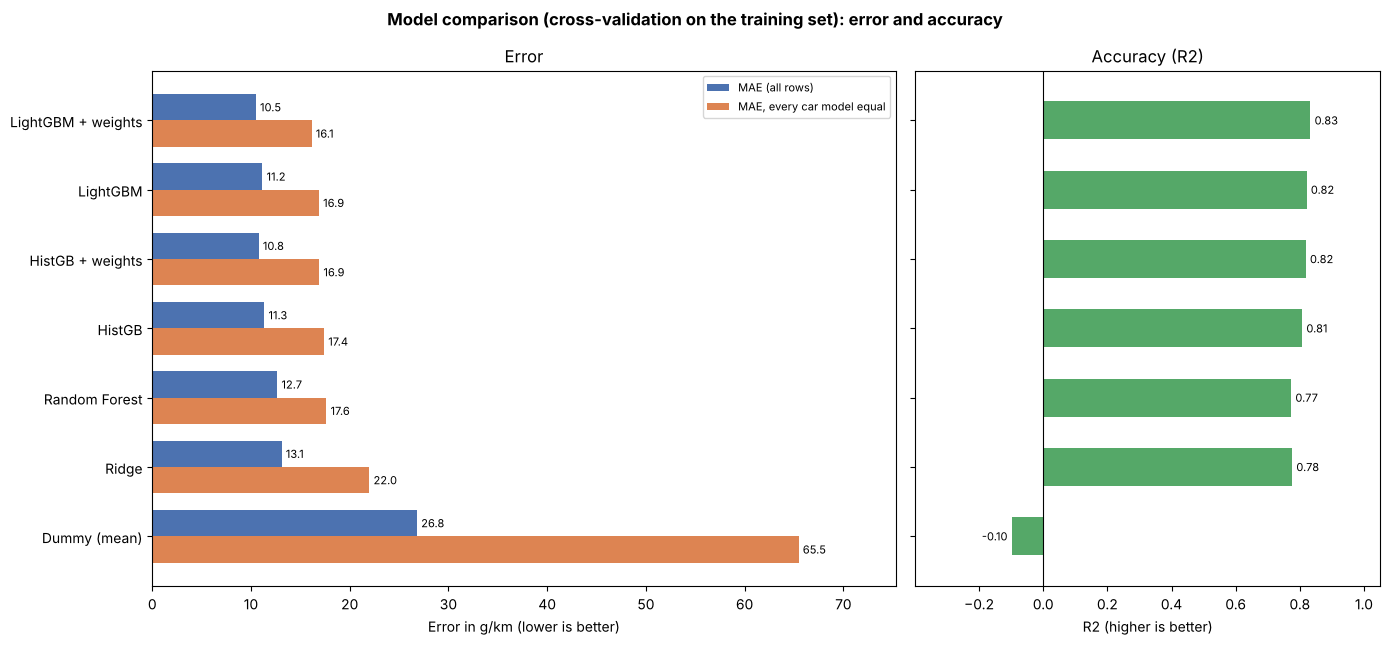

In [ ]:
# =============================================================================
# SECTION 14. MODEL COMPARISON (grouped 5-fold CV on the TRAINING set only)
# WHY: so far I have only compared Ridge and HistGB. I have added
#   - a DUMMY baseline (always predicts the training mean): any real model must beat it clearly,
#   - Random Forest and LightGBM (other tree ensembles),
#   - sample weighting (power 0.5): gives rarer car models more influence, which should
#     reduce the van bias.
# The test set is NOT touched here.
# =============================================================================
import time, warnings
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.pipeline import Pipeline
warnings.filterwarnings("ignore")

def make_dummy():
    return Pipeline([("prep", tree_preprocessor()), ("m", DummyRegressor(strategy="mean"))])

def make_rf():
    # Random forest cannot use integer codes as categories -> use the one-hot pipeline
    return Pipeline([("prep", linear_preprocessor()),
                     ("m", RandomForestRegressor(n_estimators=150, min_samples_leaf=3, n_jobs=-1, random_state=0))])

try:
    import lightgbm as lgb
    def make_lgbm():
        return Pipeline([("prep", linear_preprocessor()),
                         ("m", lgb.LGBMRegressor(n_estimators=300, learning_rate=0.05, num_leaves=31,
                                                 random_state=0, verbose=-1))])
    HAS_LGBM = True
except ImportError:
    HAS_LGBM = False
    print("lightgbm is not installed (pip install lightgbm) -> LightGBM rows are skipped")

candidates = [("Dummy (mean)",        make_dummy, 0.0),
              ("Ridge",               make_ridge, 0.0),
              ("HistGB",              make_hgb,   0.0),
              ("HistGB + weights",    make_hgb,   0.5),
              ("Random Forest",       make_rf,    0.0)]
if HAS_LGBM:
    candidates += [("LightGBM",           make_lgbm, 0.0),
                   ("LightGBM + weights", make_lgbm, 0.5)]

rows = {}
for name, factory, wp in candidates:
    t0 = time.time()
    per_repeat = []                                     # one set of scores for each random fold assignment
    for seed in SEEDS:
        oof = cv_oof(factory, X_train, y_train, g_train, weight_power=wp, seed=seed)
        per_repeat.append(metrics(y_train, oof, X_train.index))
    rows[name] = pd.DataFrame(per_repeat).mean().to_dict()          # average of the 5 repeats
    print(f"{name:20s} done in {time.time() - t0:5.1f}s")

cv_table = pd.DataFrame(rows).T.sort_values("MAE_model_weighted")
print("\nCross-validated results (g/km, lower MAE = better; average of 5 repeats):")
print(cv_table.round(2))


# * Dummy shows the cost of knowing nothing. Every other row should be far below it.
# * 'MAE' is dominated by vans. 'MAE_model_weighted' and 'MAE_other' show how the model does on the
#   many other car models: they are always HIGHER than plain MAE, i.e. plain MAE is optimistic.
# * Compare "X" with "X + weights": if MAE_model_weighted drops (and MAE does not get worse), the
#   weighting is useful.

def plot_model_comparison(table, title, path):
    """Two panels, one row per model, best model on top.
       LEFT  = ERROR   : MAE (all rows) and MAE with every car model counted equally; lower is better.
       RIGHT = ACCURACY: R2, the share of the CO2 variation the model explains (1 = perfect); higher is better."""
    t = table.sort_values("MAE_model_weighted")
    y_pos = np.arange(len(t))
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 0.62 * len(t) + 2.2), sharey=True,
                                   gridspec_kw={"width_ratios": [1.6, 1]})
    h = 0.38
    b1 = ax1.barh(y_pos - h / 2, t["MAE"], h, color="#4c72b0", label="MAE (all rows)")
    b2 = ax1.barh(y_pos + h / 2, t["MAE_model_weighted"], h, color="#dd8452", label="MAE, every car model equal")
    ax1.bar_label(b1, fmt="%.1f", padding=3, fontsize=8)
    ax1.bar_label(b2, fmt="%.1f", padding=3, fontsize=8)
    ax1.set(xlabel="Error in g/km (lower is better)", title="Error")
    ax1.set_xlim(0, t["MAE_model_weighted"].max() * 1.15)
    ax1.legend(loc="upper right", fontsize=8)
    b3 = ax2.barh(y_pos, t["R2"], 0.55, color="#55a868")
    ax2.bar_label(b3, fmt="%.2f", padding=3, fontsize=8)
    ax2.axvline(0, color="k", lw=0.8)
    ax2.set(xlabel="R2 (higher is better)", title="Accuracy (R2)")
    ax2.set_xlim(min(0, t["R2"].min()) - 0.3, 1.05)
    ax1.set_yticks(y_pos); ax1.set_yticklabels(t.index); ax1.invert_yaxis()
    fig.suptitle(title, fontsize=12, fontweight="bold")
    plt.tight_layout()
    plt.savefig(path, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()

plot_model_comparison(cv_table[["MAE", "MAE_model_weighted", "R2"]],
                      "Model comparison (cross-validation on the training set): error and accuracy",
                      os.path.join(FIG_DIR, "Fig9_model_comparison.png"))
# HOW TO READ THE FIGURE: left = how far off the predictions are (shorter is better), right = R2, the accuracy
# of the model (longer is better). A good model is short on the left AND long on the right.

## Section 15: Can tuning improve the model?
This section takes the best model of Section 14 (LightGBM with sample weights) with its starting settings and tries 8 random combinations of settings (hyper-parameters): number of trees, learning rate, size of each tree, minimum cars per leaf, share of rows and columns per tree, and a penalty on extreme values. Each combination is tested with the same 5 repeats of cross-validation on the training set. Only 8 tries, because with many tries the winner is partly just lucky.
**Decision rule.** The tuned settings are ADOPTED only if they are better than the starting settings in at least 4 of the 5 repeats on BOTH numbers: MAE (every row counts, so the vans dominate) and MAE_equal (every car model counts the same, so it reflects ordinary cars). A change that helps one number and hurts the other is a trade-off, not an improvement, and one single comparison can be lucky or unlucky because it depends on which car models share a fold.
**Tried and not used.** We also tried a new feature, power divided by mass (kW per 100 kg). It did not give a consistent gain, so it is not used.
**Result.** Read the printed table. If the tuned settings are not adopted, the final model keeps the starting settings: LightGBM with sample weights and the 7 features.

In [17]:
# SECTION 15 (code), step 1: which model won in Section 14, and helper functions
import time

best_name = cv_table.index[0]
print("Best model of the comparison (lowest MAE_model_weighted):", best_name)
if best_name != "LightGBM + weights":
    print("NOTE: the winner is not LightGBM + weights. Tell your teammate / advisor before going on: the next sections assume it.")

START_PARAMS = dict(n_estimators=300, learning_rate=0.05, num_leaves=31)    # the settings used in Section 14

def make_lgbm_tuned(params):
    return Pipeline([("prep", linear_preprocessor()),
                     ("m", lgb.LGBMRegressor(random_state=0, verbose=-1, **params))])

def cv_scores(make_model):
    """One row per repeat (5 random fold assignments), two columns (lower = better):
       MAE       = average error over all rows (dominated by the vans)
       MAE_equal = average error when every CAR MODEL counts the same (fairer for ordinary cars)"""
    rows = []
    for seed in SEEDS:
        oof = cv_oof(make_model, X_train, y_train, g_train, weight_power=0.5, seed=seed)
        err = (y_train - oof).abs()
        rows.append({"MAE": err.mean(),
                     "MAE_equal": np.average(err, weights=1.0 / n_variants.loc[X_train.index])})
    return pd.DataFrame(rows)

start_scores = cv_scores(lambda: make_lgbm_tuned(START_PARAMS))       # starting settings, 5 repeats

Best model of the comparison (lowest MAE_model_weighted): LightGBM + weights


In [18]:
# SECTION 15 (code), step 2: try 8 random settings (takes several minutes), keep the best ONLY if it clearly wins
search_space = dict(
    n_estimators=[200, 400, 600],        # number of small trees: more = more detail, slower, can over-fit
    learning_rate=[0.03, 0.05, 0.1],     # how big each tree's correction is: small = careful but needs more trees
    num_leaves=[15, 31, 63],             # how complex each tree is: bigger = can over-fit
    min_child_samples=[10, 20, 50],      # minimum cars per leaf: bigger = smoother, less memorising
    subsample=[0.7, 1.0],                # share of rows each tree sees (0.7 = randomness against over-fitting)
    colsample_bytree=[0.7, 1.0],         # share of columns each tree sees
    reg_lambda=[0, 1, 10])               # penalty on extreme values: bigger = more cautious

tried, all_scores = [], []
t0 = time.time()
for params in ParameterSampler(search_space, n_iter=8, random_state=0):
    full_params = {**params, "subsample_freq": 1 if params["subsample"] < 1 else 0}   # LightGBM needs this to use subsample
    all_scores.append(cv_scores(lambda: make_lgbm_tuned(full_params)))                # 5 repeats each
    tried.append(full_params)
print(f"8 combinations tested (5 repeats each) in {time.time() - t0:.0f}s")

best_i = int(np.argmin([s["MAE_equal"].mean() for s in all_scores]))
best_scores = all_scores[best_i]

wins_equal = int((best_scores["MAE_equal"].values < start_scores["MAE_equal"].values).sum())
wins_plain = int((best_scores["MAE"].values < start_scores["MAE"].values).sum())
USE_TUNED = wins_equal >= 4 and wins_plain >= 4
BEST_PARAMS = tried[best_i] if USE_TUNED else START_PARAMS

comparison = pd.DataFrame(
    {"MAE": [start_scores["MAE"].mean(), best_scores["MAE"].mean()],
     "MAE_equal": [start_scores["MAE_equal"].mean(), best_scores["MAE_equal"].mean()],
     "repeats won on MAE (of 5)": ["-", wins_plain],
     "repeats won on MAE_equal (of 5)": ["-", wins_equal]},
    index=["starting settings", "best tuned settings"])
print("\nBest tuned settings:", tried[best_i])
print("\nCross-validation on the training set, average of 5 repeats:")
print(comparison.round(2).to_string())
print("\nAdopt the tuned settings?", USE_TUNED)
print("Settings used from now on:", BEST_PARAMS)

8 combinations tested (5 repeats each) in 131s

Best tuned settings: {'subsample': 1.0, 'reg_lambda': 10, 'num_leaves': 63, 'n_estimators': 400, 'min_child_samples': 10, 'learning_rate': 0.1, 'colsample_bytree': 0.7, 'subsample_freq': 0}

Cross-validation on the training set, average of 5 repeats:
                       MAE  MAE_equal repeats won on MAE (of 5) repeats won on MAE_equal (of 5)
starting settings    10.49      16.14                         -                               -
best tuned settings  10.92      15.59                         2                               5

Adopt the tuned settings? False
Settings used from now on: {'n_estimators': 300, 'learning_rate': 0.05, 'num_leaves': 31}


## Section 16: Final test on the held-out test set (done once)
This section fits the final model on all training rows and grades it on the 4,533 test cars, which it has never seen, next to two reference models. Nothing is changed after looking at this result, otherwise the test set would become a second training set.
**The measures.** MAE: the average mistake in g/km. RMSE: like MAE but big mistakes count more (much larger than MAE = a few predictions are far off). R2: share of variation explained (negative = worse than guessing the test average). "Within 10 g/km": share of cars with a small error, easy to explain.
**Result.** Read the table. The test set has no vans (Section 12), so the score describes ordinary cars of unseen models. Always guessing the average and a straight-line model (Ridge) show how much the final model adds.

In [19]:
# SECTION 16 (code): final test on the held-out test set (done once)
# The final model = LightGBM with sample weights, with the settings from Section 15.
# Reference models give the number a meaning: the dummy (always the average) and Ridge (a straight-line model).

final_model = make_lgbm_tuned(BEST_PARAMS)
final_model.fit(X_train, y_train, m__sample_weight=sample_weights(X_train.index, 0.5))
FINAL_NAME = "Final model (LightGBM + weights)"

dummy = Pipeline([("prep", linear_preprocessor()), ("m", DummyRegressor(strategy="mean"))]).fit(X_train, y_train)
ridge = Pipeline([("prep", linear_preprocessor()), ("m", Ridge(alpha=1.0))]).fit(X_train, y_train)

models_on_test = {"Always predict the average": dummy,
                  "Ridge (straight-line model)": ridge,
                  FINAL_NAME: final_model}

rows, test_pred = {}, {}
for name, model in models_on_test.items():
    p = pd.Series(model.predict(X_test), index=X_test.index)
    err = y_test - p
    rows[name] = {"MAE (g/km)": err.abs().mean(),
                  "RMSE (g/km)": float(np.sqrt((err ** 2).mean())),
                  "R2": r2_score(y_test, p),
                  "% within 10 g/km": (err.abs() <= 10).mean() * 100}
    test_pred[name] = p
test_table = pd.DataFrame(rows).T
print(f"Test set: {len(X_test)} cars of {groups.loc[X_test.index].nunique()} car models never seen in training\n")
print(test_table.round(2).to_string())

Test set: 4533 cars of 90 car models never seen in training

                                  MAE (g/km)  RMSE (g/km)    R2  % within 10 g/km
Always predict the average             50.74        56.15 -1.55              5.23
Ridge (straight-line model)            17.30        21.92  0.61             36.36
Final model (LightGBM + weights)       12.83        17.07  0.76             51.38


## Section 17: Where does the model make mistakes?
This section generates Predicted vs actual CO2, the average error by fuel type, and the 10 biggest mistakes (one line per distinct car, so variants of the same car can appear several times).
**How to read it.** Points should follow the dashed diagonal; the fuel with the longest bar is the hardest (the number n shows how reliable the bar is). Error < 0 means the model predicted too HIGH.
**What we learn.** The biggest mistakes are unusual cars: the Porsche 911 Turbo (predicted far too high), the Mercedes E 300 BlueTEC Hybrid (predicted far too low: a hybrid whose battery is not among our features) and the Chevrolet Corvette Grand Sport (predicted too low). The group "other (hybrid, gas...)" has by far the largest average error, but it has very few test cars (n in the figure). Our 7 features do not describe special technology, so a few big misses are normal; this belongs in the limitations. The test set has no vans, so nothing can be said about vans here.

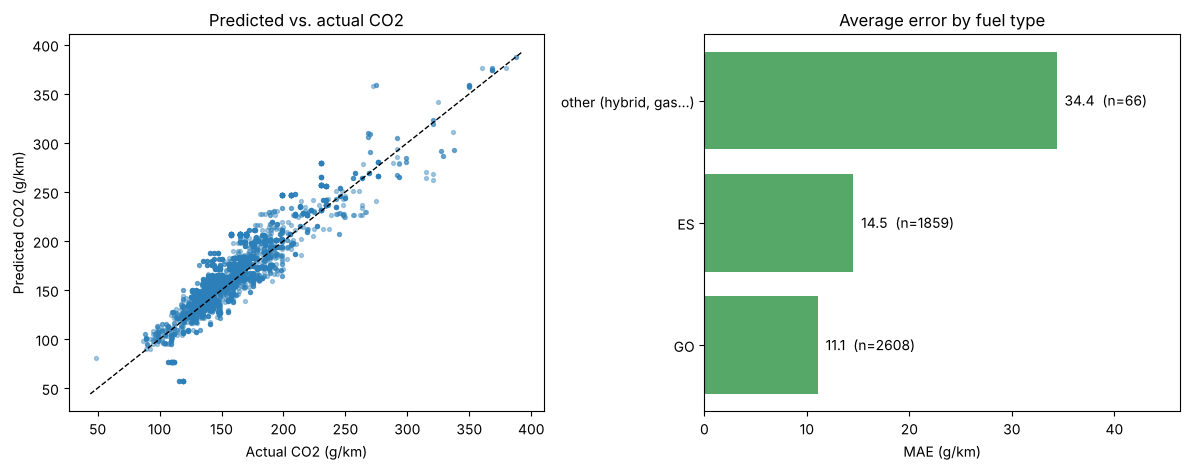

The 10 biggest mistakes (one line per distinct car):
               Brand      Model                       Description Fuel     kW    kg  Actual  Predicted  Error
42240        PORSCHE  911 TURBO                     911 TURBO 2PL   ES  368.0  1645   272.0      358.0  -86.0
42245        PORSCHE  911 TURBO               911 TURBO CABRIOLET   ES  368.0  1720   275.0      359.0  -84.0
42246        PORSCHE  911 TURBO           911 TURBO CABRIOLET 2PL   ES  368.0  1720   275.0      359.0  -84.0
7238   MERCEDES-BENZ   CLASSE E  E 300 BLUETEC HYBRID STATION WAG   GH  150.0  1955   119.0       57.0   62.0
7227   MERCEDES-BENZ   CLASSE E  E 300 BLUETEC HYBRID STATION WAG   GH  150.0  1950   119.0       57.0   62.0
7233   MERCEDES-BENZ   CLASSE E  E 300 BLUETEC HYBRID STATION WAG   GH  150.0  1955   116.0       57.0   59.0
7229   MERCEDES-BENZ   CLASSE E  E 300 BLUETEC HYBRID STATION WAG   GH  150.0  1950   116.0       57.0   59.0
1044       CHEVROLET   CORVETTE  CORVETTE Grand Sport Convertible  

In [20]:
# SECTION 17 (code): error analysis on the test set
# error = actual CO2 - predicted CO2 (error < 0 = predicted too HIGH)
pred = test_pred[FINAL_NAME]
error = y_test - pred
fuel_group = X_test["Carburant"].map(lambda f: f if f in ("GO", "ES") else "other (hybrid, gas...)")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))

axes[0].scatter(y_test, pred, s=8, alpha=0.4, color="#2c7fb8")
lims = [min(y_test.min(), pred.min()) - 5, max(y_test.max(), pred.max()) + 5]
axes[0].plot(lims, lims, "k--", lw=1)                       # perfect predictions lie on this line
axes[0].set(title="Predicted vs. actual CO2", xlabel="Actual CO2 (g/km)", ylabel="Predicted CO2 (g/km)")

mae_by_fuel = error.abs().groupby(fuel_group).mean().sort_values()
axes[1].barh(mae_by_fuel.index, mae_by_fuel.values, color="#55a868")
for i, (f, v) in enumerate(mae_by_fuel.items()):
    axes[1].text(v, i, f"  {v:.1f}  (n={int((fuel_group == f).sum())})", va="center")
axes[1].set(title="Average error by fuel type", xlabel="MAE (g/km)")
axes[1].set_xlim(0, mae_by_fuel.max() * 1.35)

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "Fig10_error_analysis.png"), dpi=300, bbox_inches="tight")
plt.show()
plt.close()

# The 10 biggest mistakes. Many rows are near-identical variants of one car, so we list each distinct car once.
meta_full = data[["Marque", "Modèle dossier", "Désignation commerciale", "Carburant", KW, CO2]]
worst = pd.DataFrame({
    "Brand": meta_full.loc[X_test.index, "Marque"],
    "Model": meta_full.loc[X_test.index, "Modèle dossier"],
    "Description": meta_full.loc[X_test.index, "Désignation commerciale"].str[:32],
    "Fuel": X_test["Carburant"], "kW": X_test["Puissance maximale (kW)"],
    "kg": X_test["masse vide euro max (kg)"],
    "Actual": y_test.round(0), "Predicted": pred.round(0), "Error": error.round(0)})
worst_sorted = worst.loc[error.abs().sort_values(ascending=False).index]
print("The 10 biggest mistakes (one line per distinct car):")
print(worst_sorted.drop_duplicates(subset=["Model", "Description", "kW", "kg", "Actual", "Predicted"]).head(10).to_string())
# HOW TO READ THIS: look at what is special about these cars (very powerful, very heavy, special technology, hybrids).
# Our features do not describe everything about a car, so a few big misses are normal.

## Section 18: From the number to the CO2 label (classes A-G)
**Idea.** The regression gives a number; we can turn it into a class afterwards. The classes are not arbitrary bins but the official French CO2 energy label for new cars (in force since 2006): A up to 100 g/km, B 101-120, C 121-140, D 141-160, E 161-200, F 201-250, G above 250 (Arrete du 10 avril 2003, annex I, as amended 10 Nov 2005, Legifrance; not part of the dataset). The label officially covers passenger cars; for the vans we use it only as a yardstick.
**Regression, then cut.** Take the final model's predicted number, round it and look up its class. The number itself is kept, so the class can be derived for any thresholds; the reverse is not possible.
**Why report "within 1 class".** The classes are ordered (D instead of E is a small mistake, A instead of G a huge one), so plain accuracy is not enough. We report the exact class, within one class, and the average distance in classes, next to the baseline "always the most common class of the training set".
**How to read it.** Classes B, C and D are only 20 g/km wide, about the size of the model's typical error, so neighbouring-class mistakes are expected and "within 1 class" is the fairer number.

In [21]:
# Classification with real thresholds (the CO2 label A-G)
# Not arbitrary bins, but the official French CO2 energy label for new cars (in force since 2006), which has exactly 7 classes:

# Class	            A	       B	   C	   D	   E	   F	  G
# CO2 (g/km)	up to 100	101-120	121-140	141-160	161-200	201-250	above 250

# CO2 label classes: Arrêté du 10 avril 2003 (annex I, as amended 10 Nov 2005), Légifrance. Not part of the dataset.
# I am using : Regression, then cut: use our final model's predicted number and look up its class.
# Predicting class D when the truth is E is a small mistake; predicting A when the truth is G is a huge one. 
# Plain "accuracy" treats both the same, so we also report within one class and the average distance in classes.

LABELS = ["A", "B", "C", "D", "E", "F", "G"]
LABEL_EDGES = [100, 120, 140, 160, 200, 250]       # upper limit (g/km) of A, B, C, D, E, F; G = above 250
LABEL_TEXT = ["<= 100", "101-120", "121-140", "141-160", "161-200", "201-250", "> 250"]

def co2_label(values):
    """CO2 in g/km -> class index 0..6 (A..G). The official label uses whole g/km, so we round first."""
    return np.searchsorted(LABEL_EDGES, np.round(np.asarray(values, dtype=float)), side="left")

y_train_cls, y_test_cls = co2_label(y_train), co2_label(y_test)
counts = pd.DataFrame({"CO2 range (g/km)": LABEL_TEXT,
                       "test cars":  np.bincount(y_test_cls,  minlength=7)}, index=LABELS)
counts["test %"] = (counts["test cars"] / counts["test cars"].sum() * 100).round(1)
print(counts)

  CO2 range (g/km)  test cars  test %
A           <= 100         46     1.0
B          101-120        201     4.4
C          121-140       1152    25.4
D          141-160       1216    26.8
E          161-200       1500    33.1
F          201-250        315     6.9
G            > 250        103     2.3


                                      exact class (%)  within 1 class (%)  \
Always 'F' (most common in training)              6.9                42.3   
Regression model, then cut                       57.9                98.5   

                                      average distance (classes)  
Always 'F' (most common in training)                         1.9  
Regression model, then cut                                   0.4  


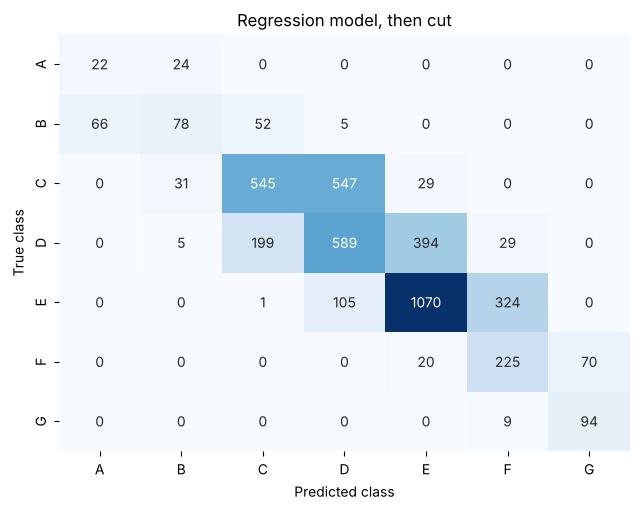

In [22]:
# Regression, then cut: round the predicted number (like the label does) and look up its class
from sklearn.metrics import confusion_matrix

pred_reg_cls = co2_label(final_model.predict(X_test))

def class_scores(pred_cls):
    distance = np.abs(pred_cls - y_test_cls)            # how many classes away from the truth
    return {"exact class (%)": (distance == 0).mean() * 100,
            "within 1 class (%)": (distance <= 1).mean() * 100,
            "average distance (classes)": distance.mean()}

most_common = np.bincount(y_train_cls).argmax()          # the class that is most frequent in training
class_table = pd.DataFrame({
    f"Always '{LABELS[most_common]}' (most common in training)": class_scores(np.full(len(y_test_cls), most_common)),
    "Regression model, then cut": class_scores(pred_reg_cls)}).T
print(class_table.round(1))

# Confusion matrix: rows = true class, columns = predicted class, numbers = test cars.
plt.figure(figsize=(6.5, 5.2))
cm = confusion_matrix(y_test_cls, pred_reg_cls, labels=range(7))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, xticklabels=LABELS, yticklabels=LABELS)
plt.title("Regression model, then cut"); plt.xlabel("Predicted class"); plt.ylabel("True class")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "Fig12_label_confusion.png"), dpi=300, bbox_inches="tight")
plt.show()
plt.close()
# HOW TO READ: the diagonal = correct. Numbers next to the diagonal = one class off (small mistake).

## Section 19: Predict a new car, and save the model
The function `predict_co2(...)` takes fuel, power, mass, body type, gearbox type, number of gears and the hybrid flag and returns the predicted CO2. The model is saved so it can be reloaded without retraining.
**Check.** Three example cars: the small petrol car should come out lowest and the large SUV highest.

In [23]:
# SECTION 19 (code): predict the CO2 of a new car, and save the model
import joblib

def predict_co2(carburant, power_kw, mass_kg, carrosserie, boite_type, nb_rapports, hybride=0):
    """carburant: GO = diesel, ES = petrol, EH = petrol hybrid ...  boite_type: M = manual, A = automatic ..."""
    car = pd.DataFrame([{"Carburant": carburant, "Hybride": hybride, "Puissance maximale (kW)": power_kw,
                         "masse vide euro max (kg)": mass_kg, "Carrosserie": carrosserie,
                         "boite_type": boite_type, "nb_rapports": nb_rapports}])
    return float(final_model.predict(car[X_train.columns])[0])      # same columns, same order as in training

examples = [("Small petrol hatchback", dict(carburant="ES", power_kw=66,  mass_kg=1100, carrosserie="BERLINE", boite_type="M", nb_rapports=5)),
            ("Diesel estate car",      dict(carburant="GO", power_kw=110, mass_kg=1650, carrosserie="BREAK",   boite_type="A", nb_rapports=7)),
            ("Large petrol SUV",       dict(carburant="ES", power_kw=300, mass_kg=2300, carrosserie="TS TERRAINS/CHEMINS", boite_type="A", nb_rapports=8))]
for label, car in examples:
    print(f"{label:25s} -> predicted CO2: {predict_co2(**car):6.1f} g/km")

os.makedirs("models", exist_ok=True)
joblib.dump(final_model, "models/co2_final_model.joblib")           # reload later with joblib.load(...)
print("\nSaved: models/co2_final_model.joblib")

Small petrol hatchback    -> predicted CO2:  114.6 g/km
Diesel estate car         -> predicted CO2:  144.7 g/km
Large petrol SUV          -> predicted CO2:  280.0 g/km

Saved: models/co2_final_model.joblib


## Section 20: Conclusion
The numbers below are copied from the tables printed above in this run. If you run the notebook again, check them against the printed tables.

**What I did.** I predicted the CO2 emissions (g/km) of cars from 7 pieces of design information (fuel, power, mass, body type, gearbox type, number of gears, hybrid or not), with the data split by car model so that the test cars are models the model has never seen.

**Result.** On the 4,533 test cars (90 car models never seen in training) the final model (LightGBM with sample weights) is off by 12.8 g/km on average (RMSE 17.1, R2 0.76) and 51% of the predictions are within 10 g/km. Always guessing the average is off by 50.7 g/km, a straight-line model (Ridge) by 17.3 g/km. Turned into the official CO2 label A-G, the predictions give the exact class for 57.9% of the cars and a class at most one step away for 98.5% (always guessing the most common class: 6.9% and 42.3%).

**What worked**
- Splitting by car model and choosing the features only on the training part, so the test result is an honest estimate for a new design.
- Dropping every column that is measured in the same lab test as CO2 or computed from it. Mixed consumption alone brings the error down to about 1 g/km, which is exactly why it must not be used.
- Mass, power, number of gears and fuel are the features that matter: removing any of them clearly raises the error in the ablation (mass +2.6, power +1.2, gears +1.1, fuel +0.9 g/km).
- Sample weights: LightGBM with weights is the best of the 7 models in cross-validation (equal-weight MAE 16.1 g/km, against 21.99 for Ridge and 65.5 for the dummy). Weights help both HistGB and LightGBM.
- Regression, then cut: the model gives the number, and the label class follows from it for any thresholds.

**What did not work, and why**
- One model per fuel type, a power-to-weight feature and tuned settings did not give a consistent gain, so we kept one global model, the 7 features and the starting settings. The tuned settings lowered the equal-weight error (16.14 to 15.59, in 5 of 5 repeats) but raised the plain MAE (10.49 to 10.92, better in only 2 of 5): a trade-off, not an improvement.
- Body type and hybrid show almost no effect in the ablation (+0.1 and 0.0 g/km). They are kept for physical reasons, and Hybride is almost the same information as the fuel code.
- Brand lowers the error slightly (-0.35 g/km) but is left out on purpose: it identifies the maker, not the design, and 87% of the rows are Mercedes-Benz.
- Hybrids, gas cars and special cars are predicted badly (largest mistakes: Porsche 911 Turbo, Mercedes E 300 hybrid, Corvette), because battery, engine and technology details are not among the features.

**Limits to state honestly**
- The data are a 2013 catalogue of laboratory values, and 87% of the rows are Mercedes-Benz (three van models alone are 73%).
- The test set contains no vans, and one car model (CLASSE E) is about 63% of its rows, so the test score describes ordinary cars and is noisy.
- The classes B, C and D are only 20 g/km wide, about the size of the typical error, so the exact class is less reliable than "within one class".

**What I would do with more time or data**
- More cars from other makers, especially hybrids and cars with special technology, and a more recent catalogue.
- Features that describe the car better (engine displacement, turbo, battery or hybrid system, aerodynamics), then re-test body type and hybrid.
- Repeat the group split with several seeds to measure how uncertain the test score is.
- Compare with the classification approach of the group project on the same split (by car model) and the same A-G classes.